# Webinar: Unsupervised Learning, Clustering, dan PCA
## Aplikasi untuk Segmentasi Pasar dan Wilayah Ekonomi Indonesia

**Mata kuliah/program:** Introduction to Data Science for Economics  
**Bahasa:** Indonesia  
**Lingkungan yang disarankan:** Google Colab atau Jupyter Notebook

### Tujuan pembelajaran
Setelah mengikuti materi dan praktikum ini, peserta diharapkan mampu:

1. Menjelaskan perbedaan *Supervised Learning* dan *Unsupervised Learning*.
2. Mengidentifikasi algoritma-algoritma dalam *Unsupervised Learning*.
3. Menjelaskan konsep dan tujuan *Clustering*.
4. Menjelaskan aplikasi clustering untuk *Recommendation System*, *Targeted Marketing*, dan *Customer Segmentation*.
5. Membedakan *Regression*, *Classification*, dan *Clustering*.
6. Melakukan analisis menggunakan *K-Means Clustering* dan *Hierarchical Clustering*.
7. Menjelaskan serta menerapkan *Principal Component Analysis* (PCA).
8. Menginterpretasikan hasil segmentasi pasar dan pengelompokan wilayah ekonomi.

### Alur praktikum
Kita mulai dari konsep, memuat dan membersihkan data, melakukan eksplorasi, membangun model clustering, mengevaluasi model, memvisualisasikan hasil dengan PCA, lalu menerjemahkan hasil menjadi insight ekonomi.

> **Catatan dataset:** Notebook sumber menggunakan dataset *Klasifikasi Tingkat Kemiskinan di Indonesia* dari repositori GitHub yang dicantumkan pada notebook awal. Ketersediaan URL dan struktur kolom dapat berubah. Jika pengambilan data gagal, unduh file CSV dari repositori tersebut dan unggah ke Google Colab, lalu sesuaikan bagian pemuatan data.

## 1. Supervised Learning vs Unsupervised Learning

### Supervised Learning
*Supervised Learning* adalah metode pembelajaran mesin yang menggunakan data berlabel. Artinya, data pelatihan memiliki variabel input (fitur) dan jawaban/target yang ingin diprediksi.

Contoh ekonomi:
- Input: pendapatan, riwayat kredit, rasio utang.
- Target: status gagal bayar (1 = gagal bayar, 0 = tidak).
- Tujuan: mempelajari pola agar model dapat memprediksi status calon debitur baru.

### Unsupervised Learning
*Unsupervised Learning* menggunakan data tanpa label target. Algoritma berusaha menemukan struktur, pola, kemiripan, atau kelompok yang tersembunyi di dalam data.

Contoh ekonomi:
- Input: tingkat kemiskinan, IPM, pendidikan, pengeluaran, dan pengangguran setiap kabupaten/kota.
- Tidak ada label kelompok yang diberikan sebelumnya.
- Tujuan: menemukan kelompok wilayah yang memiliki karakteristik sosial-ekonomi serupa.

| Aspek | Supervised Learning | Unsupervised Learning |
|---|---|---|
| Label/target | Tersedia | Tidak tersedia |
| Tujuan | Prediksi target | Menemukan pola/struktur |
| Contoh tugas | Regresi, klasifikasi | Clustering, reduksi dimensi |
| Evaluasi umum | Accuracy, RMSE, F1-score, dll. | Silhouette, Davies-Bouldin, interpretasi |

**Inti:** supervised learning belajar dari contoh yang sudah memiliki jawaban; unsupervised learning mencari pola tanpa diberi jawaban kelompok terlebih dahulu.

## 2. Algoritma dan tugas dalam Unsupervised Learning

Unsupervised Learning bukan hanya clustering. Beberapa kelompok tugas yang umum adalah:

| Tugas | Tujuan | Contoh algoritma/metode | Contoh ekonomi |
|---|---|---|---|
| Clustering | Mengelompokkan observasi yang mirip | K-Means, Hierarchical/Agglomerative, DBSCAN, Gaussian Mixture Model (GMM) | Segmentasi konsumen atau wilayah |
| Dimensionality Reduction | Merangkum banyak variabel menjadi lebih sedikit dimensi | PCA, t-SNE, UMAP | Visualisasi indikator ekonomi |
| Association Rule Learning | Menemukan kombinasi item yang sering muncul bersama | Apriori, FP-Growth | Market basket analysis |
| Anomaly Detection | Menemukan observasi yang tidak biasa | Isolation Forest, Local Outlier Factor | Deteksi transaksi atau wilayah dengan pola ekstrem |

Notebook ini berfokus pada K-Means, Hierarchical Clustering, GMM sebagai pembanding, serta PCA untuk reduksi dimensi dan visualisasi.

**Catatan:** DBSCAN, Apriori, t-SNE, dan UMAP diperkenalkan secara konseptual di sini; implementasi utama praktikum adalah K-Means, Hierarchical Clustering, dan PCA.

## 3. Apa itu Clustering?

*Clustering* adalah proses mengelompokkan observasi berdasarkan kemiripan karakteristiknya. Observasi di dalam cluster yang sama diharapkan relatif mirip, sedangkan observasi dari cluster berbeda diharapkan relatif tidak mirip.

Contoh:
- Konsumen dikelompokkan berdasarkan pendapatan dan pola belanja.
- Kabupaten/kota dikelompokkan berdasarkan kemiskinan, pendidikan, IPM, dan akses infrastruktur.
- Produk dikelompokkan berdasarkan pola pembelian konsumen.

### Bagaimana clustering bekerja?
1. Menentukan fitur yang akan digunakan.
2. Mengukur kemiripan atau jarak antarobservasi.
3. Menjalankan algoritma untuk membentuk kelompok.
4. Mengevaluasi kualitas kelompok.
5. Memberi makna/label deskriptif pada setiap kelompok berdasarkan karakteristiknya.

### Mengapa skala data penting?
Algoritma berbasis jarak dapat dipengaruhi oleh perbedaan skala. Misalnya, PDRB bernilai sangat besar, sedangkan tingkat kemiskinan berupa persentase. Tanpa standardisasi, PDRB berpotensi mendominasi perhitungan jarak.

## 4. Aplikasi Clustering dalam ekonomi dan bisnis

### 4.1 Customer Segmentation
Mengelompokkan pelanggan berdasarkan karakteristik, misalnya:
- pendapatan;
- frekuensi transaksi;
- nilai belanja rata-rata;
- kategori produk yang dibeli;
- respons terhadap promosi.

Hasilnya dapat berupa segmen pelanggan bernilai tinggi, pelanggan rutin, pelanggan sensitif harga, atau pelanggan yang mulai tidak aktif. Nama segmen harus ditentukan berdasarkan profil data, bukan diasumsikan sejak awal.

### 4.2 Targeted Marketing
Setelah segmen ditemukan, perusahaan dapat merancang penawaran yang berbeda. Contohnya, pelanggan yang sering membeli tetapi sensitif harga dapat menerima promosi bundling, sedangkan pelanggan dengan nilai transaksi tinggi dapat menerima program loyalitas.

Clustering membantu menemukan segmen; keputusan kampanye tetap memerlukan pertimbangan biaya, etika, privasi, dan pengujian efektivitas.

### 4.3 Recommendation System
Sistem rekomendasi dapat menggunakan kemiripan pengguna (*user-based*) atau kemiripan produk (*item-based*). Clustering dapat membantu:
- mengelompokkan pengguna dengan pola preferensi serupa;
- mengelompokkan produk dengan karakteristik atau pola pembelian serupa;
- mempersempit kandidat produk yang akan direkomendasikan.

**Penting:** sistem rekomendasi tidak selalu menggunakan clustering. Metode lain meliputi *collaborative filtering*, *content-based filtering*, dan pendekatan hybrid. Clustering dapat menjadi salah satu komponen pendukung.

### 4.4 Segmentasi wilayah ekonomi
Pemerintah atau lembaga pembangunan dapat mengelompokkan kabupaten/kota berdasarkan indikator sosial-ekonomi untuk membantu:
- pemetaan karakteristik wilayah;
- penentuan prioritas program;
- desain intervensi yang berbeda antarwilayah;
- evaluasi ketimpangan dan kebutuhan infrastruktur.

Cluster bukan peringkat “baik” atau “buruk”. Interpretasinya harus mempertimbangkan indikator, konteks wilayah, dan tahun data.

## 5. Regression vs Classification vs Clustering

| Metode | Jenis pembelajaran | Target diketahui? | Output | Contoh |
|---|---|---:|---|---|
| Regression | Supervised | Ya | Angka kontinu | Memprediksi PDRB |
| Classification | Supervised | Ya | Kategori yang sudah ditentukan | Memprediksi status kemiskinan |
| Clustering | Unsupervised | Tidak | Kelompok yang ditemukan dari data | Mengelompokkan kabupaten/kota |

Cara mudah mengingat:
- **Regression:** “Berapa nilainya?”
- **Classification:** “Masuk kelas yang mana?” (kelas sudah ditentukan saat pelatihan)
- **Clustering:** “Kelompok alami apa yang tampak di data?” (kelompok belum diketahui sebelumnya)

Satu dataset dapat digunakan untuk tugas yang berbeda. Jika label kemiskinan dipakai sebagai target untuk memprediksi kelas, itu klasifikasi. Jika label tersebut tidak digunakan dan algoritma mencari kelompok dari indikator ekonomi, itu clustering.

## 6. Persiapan lingkungan Python

Kita menggunakan:
- `pandas`: membaca dan mengelola data tabel.
- `numpy`: operasi numerik.
- `matplotlib` dan `seaborn`: visualisasi.
- `scikit-learn`: standardisasi, clustering, evaluasi, dan PCA.
- `scipy`: dendrogram untuk Hierarchical Clustering.

In [1]:
# Memasang pustaka yang dibutuhkan; tanda seru menjalankan perintah shell di Google Colab/Jupyter.
!pip -q install pandas numpy matplotlib seaborn scikit-learn scipy

# Mengimpor pandas untuk membaca dan mengolah data berbentuk tabel.
import pandas as pd

# Mengimpor numpy untuk perhitungan numerik dan transformasi matematis.
import numpy as np

# Mengimpor matplotlib untuk membuat grafik.
import matplotlib.pyplot as plt

# Mengimpor seaborn untuk membuat visualisasi statistik.
import seaborn as sns

# Mengimpor warnings agar pesan peringatan yang tidak esensial tidak memenuhi output.
import warnings

# Mengatur agar peringatan disembunyikan; saat debugging, baris ini dapat dinonaktifkan.
warnings.filterwarnings("ignore")

# Mengatur tema grafik agar tampil konsisten dan mudah dibaca.
sns.set_theme(style="whitegrid")

# Mengatur agar pandas menampilkan maksimal 50 kolom pada output tabel.
pd.set_option("display.max_columns", 50)

# Mengatur jumlah angka desimal yang ditampilkan pandas menjadi dua digit.
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## 7. Memuat dataset wilayah ekonomi Indonesia

Dataset yang digunakan pada notebook sumber berjudul **Klasifikasi Tingkat Kemiskinan di Indonesia**. Variabel yang dicantumkan meliputi tingkat kemiskinan, rata-rata lama sekolah, pengeluaran per kapita, IPM, umur harapan hidup, akses sanitasi, akses air minum, pengangguran, partisipasi angkatan kerja, dan PDRB.

Kita tidak menggunakan kolom klasifikasi kemiskinan sebagai fitur clustering. Jika label tersebut dimasukkan, tujuan analisis menjadi tercampur dengan label yang sudah tersedia.

In [2]:
# Menyimpan alamat file CSV mentah dari repositori yang digunakan notebook sumber.
url = "https://raw.githubusercontent.com/JangAY/Klasifikasi_Kemiskinan_Indonesia/main/Klasifikasi%20Tingkat%20Kemiskinan%20di%20Indonesia.csv"

# Membaca file CSV; sep=';' berarti pemisah antar kolom adalah titik koma.
# Jika URL tidak dapat diakses, unggah CSV ke Colab lalu ganti baris ini dengan pd.read_csv('/content/nama_file.csv', sep=';').
df = pd.read_csv(url, sep=";")

# Menampilkan lima baris pertama untuk memeriksa apakah data berhasil dimuat.
display(df.head())

,Provinsi,Kab/Kota,Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),Rata-rata Lama Sekolah Penduduk 15+ (Tahun),Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),Indeks Pembangunan Manusia,Umur Harapan Hidup (Tahun),Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,Persentase rumah tangga yang memiliki akses terhadap air minum layak,Tingkat Pengangguran Terbuka,Tingkat Partisipasi Angkatan Kerja,PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah),Klasifikasi Kemiskinan
0,ACEH,Simeulue,"18,98","9,48","7,148.00","66,41","65,28","71,56","87,45","5,71","71,15","1,648,096.00",0.00
1,ACEH,Aceh Singkil,"20,36","8,68","8,776.00","69,22","67,43","69,56","78,58","8,36","62,85","1,780,419.00",1.00
2,ACEH,Aceh Selatan,"13,18","8,88","8,180.00","67,44","64,4","62,55","79,65","6,46","60,85","4,345,784.00",0.00
3,ACEH,Aceh Tenggara,"13,41","9,67","8,030.00","69,44","68,22","62,71","86,71","6,43","69,62","3,487,157.00",0.00
4,ACEH,Aceh Timur,"14,45","8,21","8,577.00","67,83","68,74","66,75","83,16","7,13","59,48","8,433,526.00",0.00


In [3]:
# Menampilkan jumlah baris dan kolom; output berbentuk (jumlah_baris, jumlah_kolom).
print("Ukuran dataset:", df.shape)

# Menampilkan daftar nama kolom agar kita mengetahui nama variabel yang tersedia.
print("\nNama kolom:")
print(df.columns.tolist())

# Menampilkan tipe data setiap kolom untuk memeriksa apakah angka terbaca sebagai numerik atau teks.
print("\nTipe data:")
print(df.dtypes)

Ukuran dataset: (999, 13)

Nama kolom:
['Provinsi', 'Kab/Kota', 'Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)', 'Rata-rata Lama Sekolah Penduduk 15+ (Tahun)', 'Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)', 'Indeks Pembangunan Manusia', 'Umur Harapan Hidup (Tahun)', 'Persentase rumah tangga yang memiliki akses terhadap sanitasi layak', 'Persentase rumah tangga yang memiliki akses terhadap air minum layak', 'Tingkat Pengangguran Terbuka', 'Tingkat Partisipasi Angkatan Kerja', 'PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)', 'Klasifikasi Kemiskinan']

Tipe data:
Provinsi                                                                 object
Kab/Kota                                                                 object
Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)          object
Rata-rata Lama Sekolah Penduduk 15+ (Tahun)                              object
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)     

## 8. Data cleaning dan pemilihan variabel

Nama kolom asli dipertahankan dalam sumber data, lalu dipetakan ke nama yang lebih ringkas agar mudah digunakan dalam kode. Nilai numerik pada sumber dapat menggunakan koma sebagai tanda desimal. Kita mengubahnya menjadi format numerik.

**Mengapa membersihkan data?** Algoritma tidak dapat menghitung jarak dengan benar jika nilai numerik masih berupa teks. Nilai kosong juga perlu ditangani sebelum pemodelan.

In [4]:
# Membuat kamus untuk memetakan nama kolom asli ke nama kolom yang lebih ringkas.
rename_map = {
    "Provinsi": "province",
    "Kab/Kota": "region",
    "Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)": "poverty_rate",
    "Rata-rata Lama Sekolah Penduduk 15+ (Tahun)": "school_years",
    "Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)": "expenditure_per_capita",
    "Indeks Pembangunan Manusia": "hdi",
    "Umur Harapan Hidup (Tahun)": "life_expectancy",
    "Persentase rumah tangga yang memiliki akses terhadap sanitasi layak": "sanitation_access",
    "Persentase rumah tangga yang memiliki akses terhadap air minum layak": "drinking_water_access",
    "Tingkat Pengangguran Terbuka": "unemployment_rate",
    "Tingkat Partisipasi Angkatan Kerja": "labor_force_participation",
    "PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)": "regional_gdp",
    "Klasifikasi Kemiskinan": "poverty_class"
}

# Mengganti nama hanya kolom yang benar-benar ditemukan pada dataset; kolom lain tidak diubah.
df = df.rename(columns={old: new for old, new in rename_map.items() if old in df.columns})

# Menampilkan nama kolom setelah proses penggantian nama.
print(df.columns.tolist())

# Menentukan variabel numerik yang akan diperiksa dan digunakan untuk clustering.
numeric_columns = [
    "poverty_rate",
    "school_years",
    "expenditure_per_capita",
    "hdi",
    "life_expectancy",
    "sanitation_access",
    "drinking_water_access",
    "unemployment_rate",
    "labor_force_participation",
    "regional_gdp"
]

# Memeriksa apakah seluruh kolom yang dibutuhkan tersedia di dalam dataset.
missing_columns = [column for column in numeric_columns if column not in df.columns]

# Menghentikan proses dengan pesan yang jelas jika ada kolom yang tidak ditemukan.
if missing_columns:
    raise ValueError(f"Kolom berikut tidak ditemukan: {missing_columns}. Periksa nama kolom pada sumber data.")

# Mengubah setiap kolom numerik satu per satu.
for column in numeric_columns:
    # Mengubah isi kolom menjadi teks sementara agar operasi pembersihan string dapat dilakukan.
    df[column] = df[column].astype(str)

    # Mengubah koma desimal menjadi titik desimal.
    df[column] = df[column].str.replace(",", ".", regex=False)

    # Menghapus spasi yang mungkin tersisip di antara karakter angka.
    df[column] = df[column].str.replace(" ", "", regex=False)

    # Mengubah teks menjadi angka; teks yang tidak dapat dikonversi akan menjadi NaN.
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Menghitung jumlah nilai kosong pada masing-masing variabel numerik.
missing_values = df[numeric_columns].isnull().sum().sort_values(ascending=False)

# Menampilkan jumlah nilai kosong agar kita dapat menilai kualitas data.
display(missing_values)

# Menghapus baris yang memiliki nilai kosong pada salah satu fitur yang digunakan.
df_clean = df.dropna(subset=numeric_columns).copy()

# Menampilkan ukuran data sebelum dan sesudah penghapusan nilai kosong.
print("Ukuran data awal:", df.shape)
print("Ukuran data setelah dibersihkan:", df_clean.shape)

['province', 'region', 'poverty_rate', 'school_years', 'expenditure_per_capita', 'hdi', 'life_expectancy', 'sanitation_access', 'drinking_water_access', 'unemployment_rate', 'labor_force_participation', 'regional_gdp', 'poverty_class']


,0
poverty_rate,485
school_years,485
expenditure_per_capita,485
hdi,485
life_expectancy,485
sanitation_access,485
drinking_water_access,485
unemployment_rate,485
labor_force_participation,485
regional_gdp,485


Ukuran data awal: (999, 13)
Ukuran data setelah dibersihkan: (514, 13)


## 9. Exploratory Data Analysis (EDA)

EDA membantu kita memahami data sebelum membangun model. Kita akan melihat:
1. Statistik deskriptif: rata-rata, standar deviasi, nilai minimum, dan maksimum.
2. Distribusi: apakah data simetris atau menceng.
3. Outlier: apakah ada nilai yang jauh dari sebagian besar observasi.
4. Korelasi: apakah dua indikator bergerak bersama secara linear.

Korelasi tidak otomatis menunjukkan hubungan sebab-akibat.

In [5]:
# Menghitung statistik deskriptif untuk semua fitur numerik.
descriptive_stats = df_clean[numeric_columns].describe().T

# Menampilkan statistik dengan variabel sebagai baris agar lebih mudah dibaca.
display(descriptive_stats)

,count,mean,std,min,25%,50%,75%,max
poverty_rate,514.00,12.27,7.46,2.38,7.15,10.46,14.89,41.66
school_years,514.00,8.44,1.63,1.42,7.51,8.30,9.34,12.83
expenditure_per_capita,514.00,"10,324.79","2,717.14","3,976.00","8,574.00","10,196.50","11,719.00","23,888.00"
hdi,514.00,69.93,6.50,32.84,66.64,69.61,73.11,87.18
life_expectancy,514.00,69.66,3.45,55.43,67.39,69.97,72.04,77.73
sanitation_access,514.00,77.20,18.58,0.00,70.22,81.80,89.88,99.97
drinking_water_access,514.00,85.14,15.70,0.00,79.04,89.79,96.40,100.00
unemployment_rate,514.00,5.06,2.64,0.00,3.18,4.56,6.53,13.37
labor_force_participation,514.00,69.46,6.40,56.39,65.07,68.95,72.34,97.93
regional_gdp,514.00,"21,964,077.48","47,904,920.44","147,485.00","3,654,291.50","8,814,925.50","19,735,101.00","460,081,046.00"


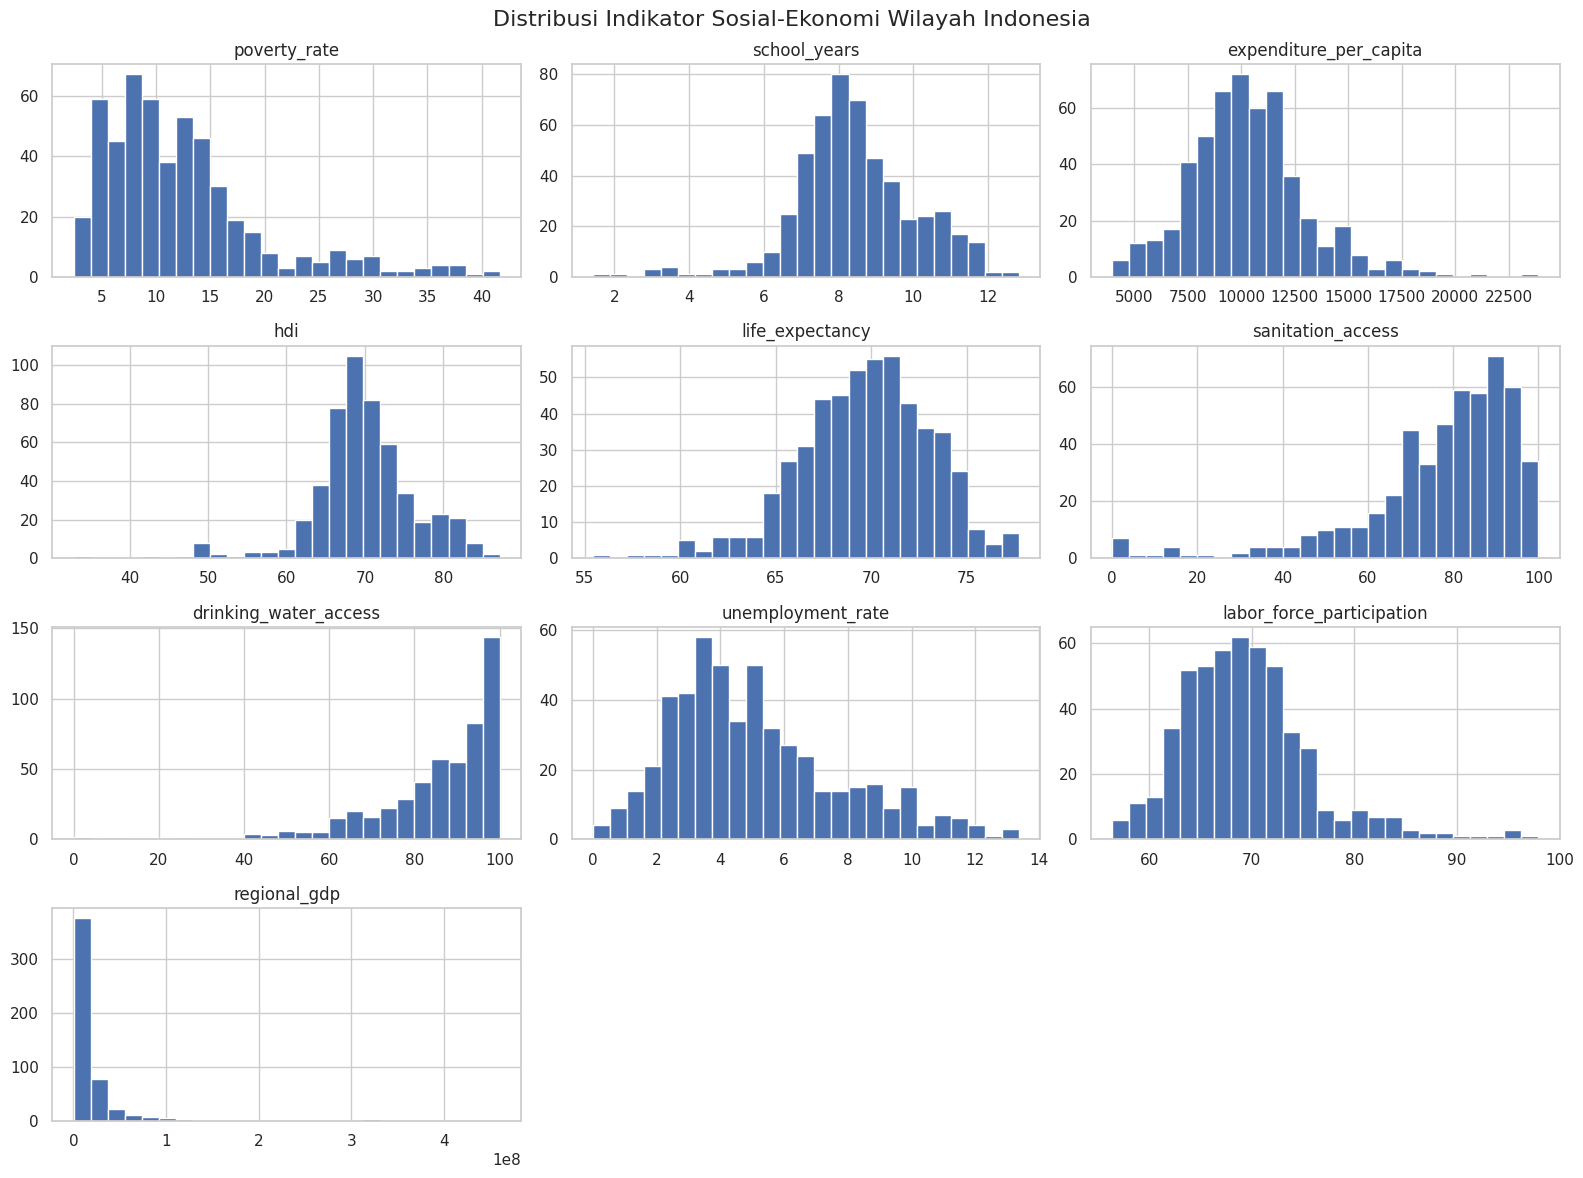

In [6]:
# Membuat histogram untuk setiap variabel numerik.
df_clean[numeric_columns].hist(figsize=(16, 12), bins=25)

# Memberikan judul utama untuk seluruh kumpulan histogram.
plt.suptitle("Distribusi Indikator Sosial-Ekonomi Wilayah Indonesia", fontsize=16)

# Mengatur jarak antar grafik agar judul dan label tidak saling bertumpuk.
plt.tight_layout()

# Menampilkan seluruh histogram.
plt.show()

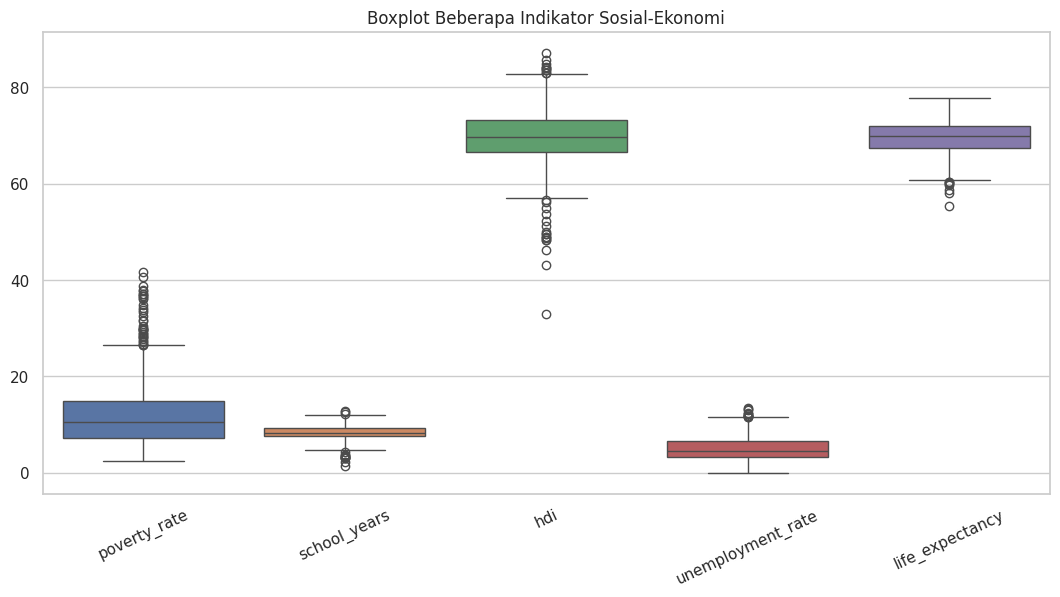

In [7]:
# Memilih beberapa indikator untuk pemeriksaan outlier melalui boxplot.
boxplot_columns = [
    "poverty_rate",
    "school_years",
    "hdi",
    "unemployment_rate",
    "life_expectancy"
]

# Menentukan ukuran area grafik.
plt.figure(figsize=(13, 6))

# Membuat boxplot untuk membandingkan sebaran indikator terpilih.
sns.boxplot(data=df_clean[boxplot_columns])

# Memutar label sumbu x agar nama variabel mudah dibaca.
plt.xticks(rotation=25)

# Memberikan judul grafik.
plt.title("Boxplot Beberapa Indikator Sosial-Ekonomi")

# Menampilkan grafik.
plt.show()

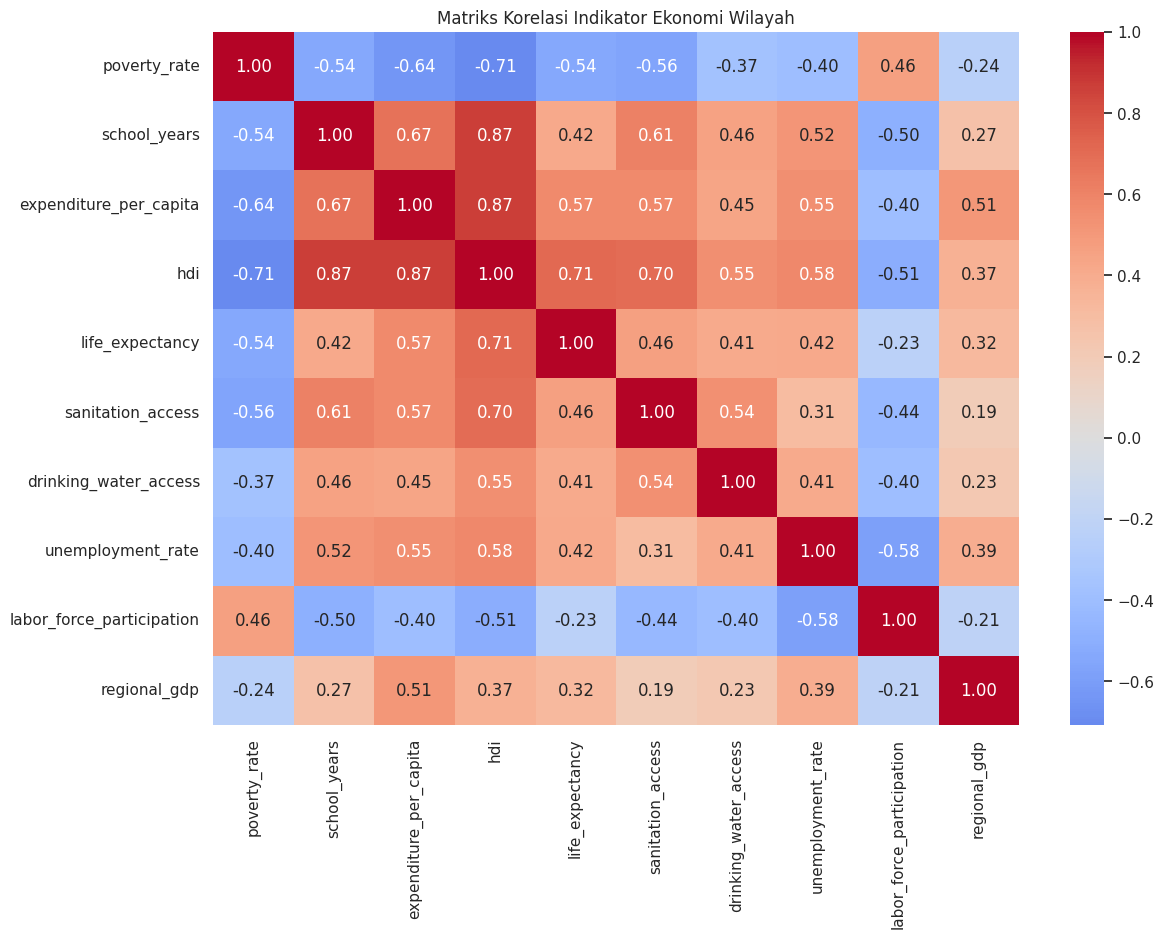

In [8]:
# Menghitung matriks korelasi antarvariabel numerik.
corr = df_clean[numeric_columns].corr()

# Menentukan ukuran grafik heatmap.
plt.figure(figsize=(13, 9))

# Membuat heatmap; angka di setiap sel menunjukkan koefisien korelasi.
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)

# Memberikan judul grafik.
plt.title("Matriks Korelasi Indikator Ekonomi Wilayah")

# Menampilkan heatmap.
plt.show()

### Panduan interpretasi EDA

Perhatikan beberapa pertanyaan berikut saat membaca output:
- Apakah IPM dan rata-rata lama sekolah memiliki korelasi positif?
- Apakah tingkat kemiskinan berkorelasi negatif dengan pengeluaran per kapita atau IPM?
- Apakah PDRB memiliki sebaran yang jauh lebih lebar dibandingkan variabel persentase?
- Apakah terdapat outlier yang mungkin memengaruhi perhitungan jarak?

Jawaban harus merujuk pada hasil aktual yang muncul dari dataset, bukan diasumsikan sebelumnya.

## 10. Feature engineering dan standardisasi

### Transformasi logaritmik
PDRB sering memiliki rentang nilai yang sangat besar. Transformasi `log1p(x)` menghitung `log(1 + x)` sehingga nilai ekstrem dapat menjadi lebih terkompresi. Transformasi ini membantu mengurangi kemencengan, tetapi tidak menghapus seluruh pengaruh outlier.

### Standardisasi
StandardScaler mengubah setiap fitur menjadi skala dengan rata-rata sekitar 0 dan standar deviasi sekitar 1. Standardisasi penting untuk algoritma yang menggunakan jarak, seperti K-Means dan Hierarchical Clustering dengan Ward linkage.

Kita tidak memasukkan nama provinsi/kabupaten/kota sebagai fitur numerik. Kita juga tidak memasukkan `poverty_class`, karena kolom itu merupakan label klasifikasi yang sudah tersedia.

In [9]:
# Membuat salinan data bersih agar data asli tetap tersedia.
df_model = df_clean.copy()

# Mengubah PDRB menggunakan log(1 + PDRB) untuk mengurangi rentang nilai yang terlalu lebar.
df_model["log_regional_gdp"] = np.log1p(df_model["regional_gdp"])

# Menampilkan PDRB asli dan hasil transformasi untuk membandingkan skala nilainya.
display(df_model[["regional_gdp", "log_regional_gdp"]].head())

,regional_gdp,log_regional_gdp
0,"1,648,096.00",14.32
1,"1,780,419.00",14.39
2,"4,345,784.00",15.28
3,"3,487,157.00",15.06
4,"8,433,526.00",15.95


In [10]:
# Menentukan fitur akhir yang akan digunakan untuk membentuk cluster.
clustering_features = [
    "poverty_rate",
    "school_years",
    "expenditure_per_capita",
    "hdi",
    "life_expectancy",
    "sanitation_access",
    "drinking_water_access",
    "unemployment_rate",
    "labor_force_participation",
    "log_regional_gdp"
]

# Membentuk matriks fitur X yang hanya berisi variabel untuk clustering.
X = df_model[clustering_features].copy()

# Menampilkan lima baris pertama matriks fitur.
display(X.head())

,poverty_rate,school_years,expenditure_per_capita,hdi,life_expectancy,sanitation_access,drinking_water_access,unemployment_rate,labor_force_participation,log_regional_gdp
0,18.98,9.48,"7,148.00",66.41,65.28,71.56,87.45,5.71,71.15,14.32
1,20.36,8.68,"8,776.00",69.22,67.43,69.56,78.58,8.36,62.85,14.39
2,13.18,8.88,"8,180.00",67.44,64.40,62.55,79.65,6.46,60.85,15.28
3,13.41,9.67,"8,030.00",69.44,68.22,62.71,86.71,6.43,69.62,15.06
4,14.45,8.21,"8,577.00",67.83,68.74,66.75,83.16,7.13,59.48,15.95


In [11]:
# Mengimpor StandardScaler untuk standardisasi fitur.
from sklearn.preprocessing import StandardScaler

# Membuat objek StandardScaler.
scaler = StandardScaler()

# Menghitung parameter standardisasi dari data dan mengubah semua fitur ke skala standar.
X_scaled = scaler.fit_transform(X)

# Mengubah hasil array menjadi DataFrame agar nama kolom dan indeks tetap mudah dikenali.
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features,
    index=df_model.index
)

# Menampilkan hasil standardisasi.
display(X_scaled_df.head())

# Menampilkan rata-rata fitur hasil standardisasi; nilainya diharapkan mendekati nol.
print("Rata-rata fitur setelah standardisasi:")
display(X_scaled_df.mean().round(3))

# Menampilkan standar deviasi fitur hasil standardisasi; nilainya diharapkan mendekati satu.
print("Standar deviasi fitur setelah standardisasi:")
display(X_scaled_df.std().round(3))

,poverty_rate,school_years,expenditure_per_capita,hdi,life_expectancy,sanitation_access,drinking_water_access,unemployment_rate,labor_force_participation,log_regional_gdp
0,0.90,0.64,-1.17,-0.54,-1.27,-0.30,0.15,0.25,0.26,-1.34
1,1.09,0.15,-0.57,-0.11,-0.65,-0.41,-0.42,1.25,-1.04,-1.28
2,0.12,0.27,-0.79,-0.38,-1.53,-0.79,-0.35,0.53,-1.35,-0.57
3,0.15,0.76,-0.85,-0.07,-0.42,-0.78,0.10,0.52,0.02,-0.75
4,0.29,-0.14,-0.64,-0.32,-0.27,-0.56,-0.13,0.79,-1.56,-0.05


Rata-rata fitur setelah standardisasi:


,0
poverty_rate,0.00
school_years,0.00
expenditure_per_capita,-0.00
hdi,0.00
life_expectancy,0.00
sanitation_access,0.00
drinking_water_access,-0.00
unemployment_rate,0.00
labor_force_participation,0.00
log_regional_gdp,0.00


Standar deviasi fitur setelah standardisasi:


,0
poverty_rate,1.00
school_years,1.00
expenditure_per_capita,1.00
hdi,1.00
life_expectancy,1.00
sanitation_access,1.00
drinking_water_access,1.00
unemployment_rate,1.00
labor_force_participation,1.00
log_regional_gdp,1.00


## 11. Menentukan jumlah cluster: Elbow Method dan Silhouette Score

K-Means meminta kita menentukan jumlah cluster, yaitu `k`.

- **Elbow Method:** melihat penurunan *inertia* (jumlah kuadrat jarak observasi ke centroid cluster). Kita mencari titik ketika penurunan mulai melandai.

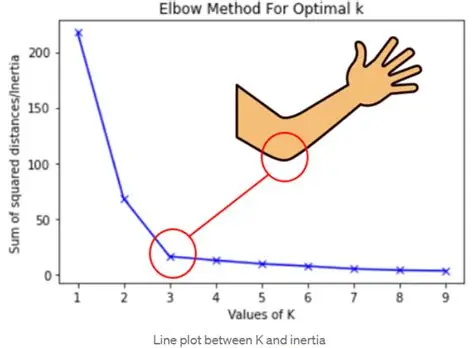
- **Silhouette Score:** mengukur seberapa dekat observasi dengan cluster sendiri dibandingkan cluster lain. Nilai mendekati 1 menunjukkan pemisahan yang lebih baik; sekitar 0 menunjukkan cluster saling tumpang tindih; nilai negatif dapat menunjukkan penempatan yang kurang sesuai.
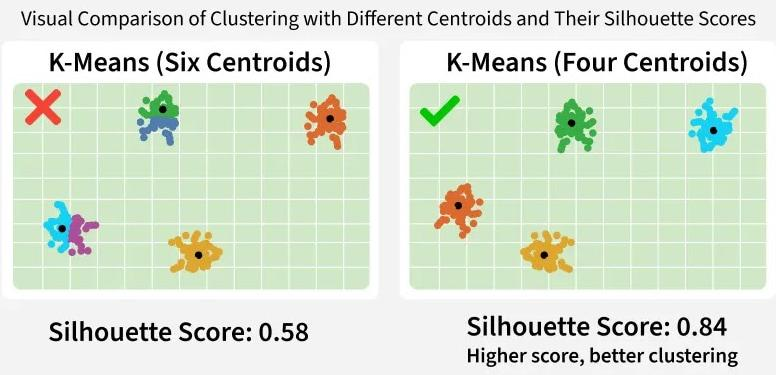

Tidak ada satu metode yang selalu menentukan jumlah cluster terbaik. Pertimbangkan metrik, ukuran cluster, kestabilan, dan interpretasi ekonomi.

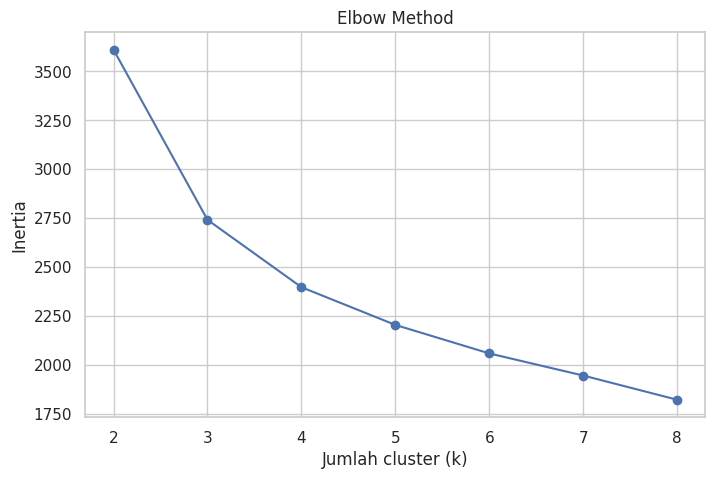

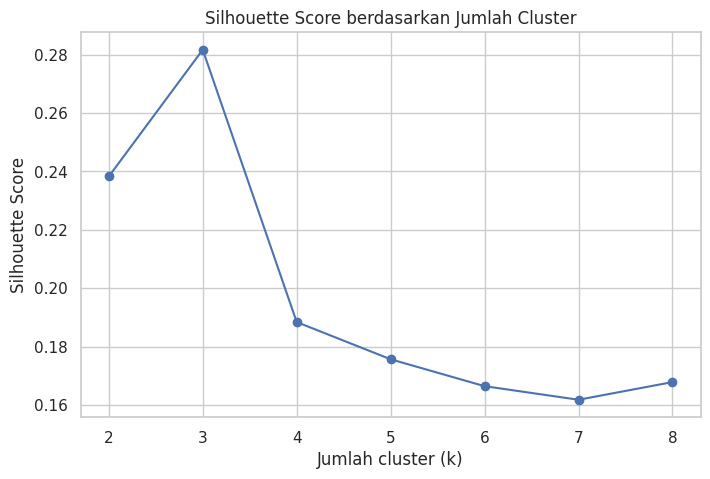

,jumlah_cluster_k,inertia,silhouette_score
0,2,"3,611.13",0.24
1,3,"2,741.90",0.28
2,4,"2,397.74",0.19
3,5,"2,204.96",0.18
4,6,"2,059.20",0.17
5,7,"1,946.23",0.16
6,8,"1,822.55",0.17


In [12]:
# Mengimpor algoritma K-Means dari scikit-learn.
from sklearn.cluster import KMeans

# Mengimpor metrik Silhouette Score untuk evaluasi hasil clustering.
from sklearn.metrics import silhouette_score

# Menyiapkan list kosong untuk menyimpan nilai inertia dari setiap jumlah cluster.
inertia_values = []

# Menyiapkan list kosong untuk menyimpan nilai silhouette dari setiap jumlah cluster.
silhouette_values = []

# Menentukan rentang jumlah cluster yang akan diuji, yaitu 2 sampai 8.
k_values = range(2, 9)

# Mengulangi proses pemodelan untuk setiap nilai k.
for k in k_values:
    # Membuat model K-Means dengan k cluster dan seed agar hasil lebih mudah direplikasi.
    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    # Melatih model dan memperoleh label cluster untuk setiap observasi.
    labels = model.fit_predict(X_scaled)

    # Menyimpan inertia model untuk kebutuhan Elbow Method.
    inertia_values.append(model.inertia_)

    # Menghitung dan menyimpan Silhouette Score untuk hasil clustering saat ini.
    silhouette_values.append(silhouette_score(X_scaled, labels))

# Membuat area grafik untuk Elbow Method.
plt.figure(figsize=(8, 5))

# Menggambar hubungan jumlah cluster dengan inertia.
plt.plot(list(k_values), inertia_values, marker="o")

# Memberi label sumbu x.
plt.xlabel("Jumlah cluster (k)")

# Memberi label sumbu y.
plt.ylabel("Inertia")

# Memberi judul grafik.
plt.title("Elbow Method")

# Menampilkan seluruh nilai k sebagai tanda pada sumbu x.
plt.xticks(list(k_values))

# Menampilkan grafik Elbow Method.
plt.show()

# Membuat area grafik untuk Silhouette Score.
plt.figure(figsize=(8, 5))

# Menggambar hubungan jumlah cluster dengan nilai silhouette.
plt.plot(list(k_values), silhouette_values, marker="o")

# Memberi label sumbu x.
plt.xlabel("Jumlah cluster (k)")

# Memberi label sumbu y.
plt.ylabel("Silhouette Score")

# Memberi judul grafik.
plt.title("Silhouette Score berdasarkan Jumlah Cluster")

# Menampilkan seluruh nilai k sebagai tanda pada sumbu x.
plt.xticks(list(k_values))

# Menampilkan grafik Silhouette Score.
plt.show()

# Menggabungkan nilai k, inertia, dan silhouette ke dalam satu tabel.
k_evaluation = pd.DataFrame({
    "jumlah_cluster_k": list(k_values),
    "inertia": inertia_values,
    "silhouette_score": silhouette_values
})

# Menampilkan tabel evaluasi untuk membantu memilih kandidat jumlah cluster.
display(k_evaluation)

In [13]:
# Mencari indeks baris dengan Silhouette Score tertinggi.
best_index = k_evaluation["silhouette_score"].idxmax()

# Mengambil nilai k pada baris tersebut sebagai kandidat jumlah cluster terbaik.
best_k = int(k_evaluation.loc[best_index, "jumlah_cluster_k"])

# Menampilkan jumlah cluster yang terpilih berdasarkan metrik silhouette.
print("Kandidat jumlah cluster berdasarkan Silhouette Score:", best_k)

Kandidat jumlah cluster berdasarkan Silhouette Score: 3


## 12. Model 1 — K-Means Clustering

K-Means adalah algoritma clustering yang membagi data ke dalam `k` kelompok. Setiap kelompok memiliki centroid (titik pusat).

K-Means clustering digunakan untuk mengelompokkan data tak berlabel ke dalam sejumlah cluster (kelompok) berdasarkan kemiripan karakteristiknya. Huruf K pada nama metode ini menyatakan jumlah kluster yang ingin dibentuk dan harus ditentukan sebelumnya oleh analis.

Langkah kerja:
1. Menentukan jumlah cluster `k`.
2. Menginisialisasi centroid.
3. Menempatkan setiap observasi ke centroid terdekat.
4. Menghitung ulang centroid berdasarkan rata-rata anggota cluster.
5. Mengulang proses sampai perpindahan anggota/centroid stabil atau batas iterasi tercapai.

**Kelebihan:** relatif cepat dan mudah dipahami.  
**Keterbatasan:** perlu menentukan `k`, sensitif terhadap skala dan outlier, serta cenderung cocok untuk cluster yang relatif kompak.
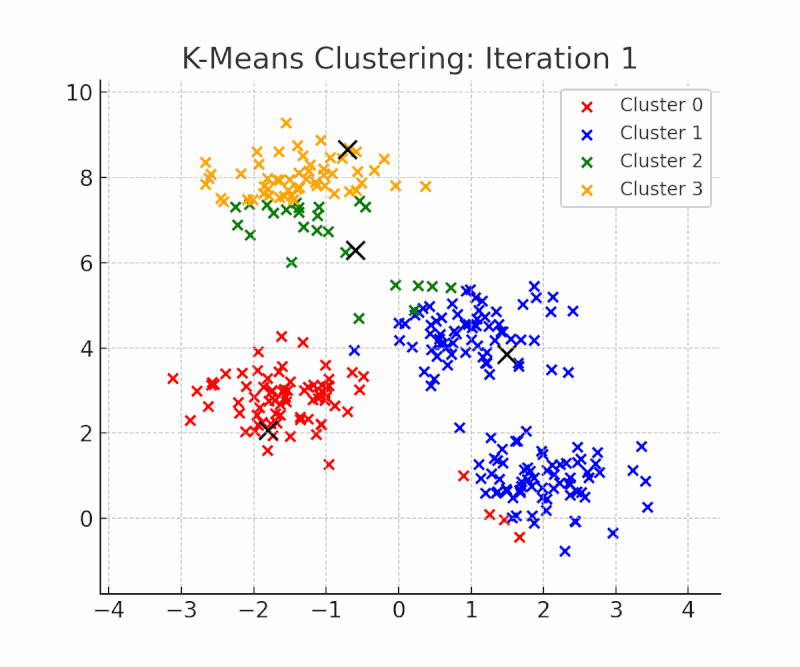

In [14]:
# Membuat model K-Means akhir menggunakan jumlah cluster kandidat yang dipilih.
kmeans_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)

# Melatih model pada data terstandardisasi dan menghasilkan label cluster.
kmeans_labels = kmeans_model.fit_predict(X_scaled)

# Menambahkan label K-Means ke tabel data untuk analisis lanjutan.
df_model["kmeans_cluster"] = kmeans_labels

# Menghitung jumlah wilayah pada setiap cluster dan mengurutkannya berdasarkan nomor cluster.
cluster_sizes_kmeans = df_model["kmeans_cluster"].value_counts().sort_index()

# Menampilkan jumlah wilayah di setiap cluster.
display(cluster_sizes_kmeans)

,count
kmeans_cluster,
0,141
1,35
2,338


## 13. Model 2 — Hierarchical/Agglomerative Clustering

*Hierarchical Clustering* membentuk struktur pengelompokan bertingkat. Pada pendekatan agglomerative:
1. Setiap observasi awalnya dianggap sebagai satu cluster.
2. Dua cluster yang paling dekat digabungkan.
3. Proses penggabungan diulang sampai jumlah cluster yang diinginkan tercapai.

`linkage="ward"` memilih penggabungan yang meminimalkan kenaikan variasi di dalam cluster. Untuk Ward linkage, jarak Euclidean digunakan.

Hierarchical clustering (pengelompokan hierarkis) adalah metode analisis machine learning tanpa pengawasan (unsupervised learning) yang mengelompokkan data ke dalam struktur bertingkat berbentuk seperti pohon yang disebut dendrogram.

**Dendrogram** adalah diagram pohon yang menunjukkan urutan dan jarak penggabungan cluster. Dendrogram membantu memahami struktur bertingkat, terutama ketika jumlah observasi tidak terlalu besar.

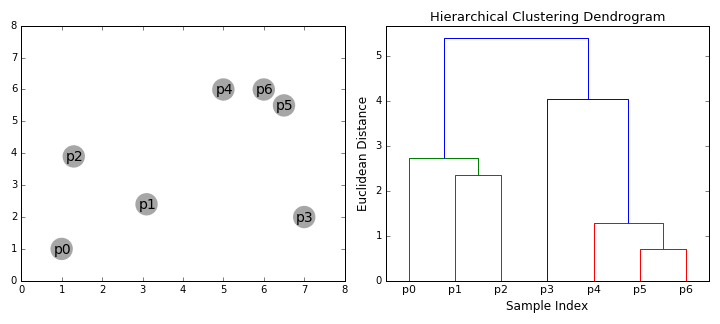

In [15]:
# Mengimpor AgglomerativeClustering untuk membangun model hierarchical clustering.
from sklearn.cluster import AgglomerativeClustering

# Membuat model agglomerative dengan jumlah cluster sama dengan kandidat best_k.
hierarchical_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)

# Menjalankan proses clustering dan memperoleh label setiap observasi.
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

# Menambahkan label hierarchical clustering ke tabel data.
df_model["hierarchical_cluster"] = hierarchical_labels

# Menghitung jumlah observasi pada setiap cluster hierarchical.
cluster_sizes_hierarchical = df_model["hierarchical_cluster"].value_counts().sort_index()

# Menampilkan ukuran setiap cluster.
display(cluster_sizes_hierarchical)

,count
hierarchical_cluster,
0,187
1,33
2,294


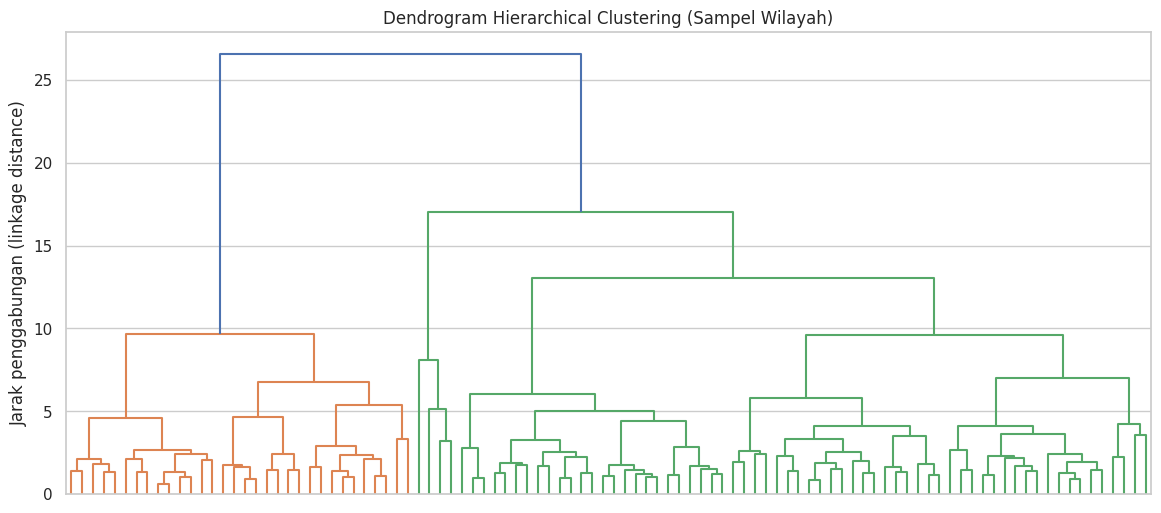

In [16]:
# Mengimpor fungsi linkage dan dendrogram dari scipy untuk membuat diagram pohon.
from scipy.cluster.hierarchy import linkage, dendrogram

# Mengambil maksimal 100 baris secara acak agar dendrogram tetap terbaca.
sample_size = min(100, len(X_scaled))

# Mengambil indeks sampel dengan seed tetap agar pemilihan sampel dapat direplikasi.
sample_indices = np.random.default_rng(42).choice(len(X_scaled), size=sample_size, replace=False)

# Membuat matriks linkage Ward dari data sampel yang sudah distandardisasi.
Z = linkage(X_scaled[sample_indices], method="ward")

# Menentukan ukuran area dendrogram.
plt.figure(figsize=(14, 6))

# Menggambar dendrogram; label observasi disembunyikan agar grafik tidak terlalu padat.
dendrogram(Z, no_labels=True, color_threshold=None)

# Memberikan judul grafik.
plt.title("Dendrogram Hierarchical Clustering (Sampel Wilayah)")

# Memberi label sumbu y sebagai jarak penggabungan.
plt.ylabel("Jarak penggabungan (linkage distance)")

# Menampilkan dendrogram.
plt.show()

**Catatan membaca dendrogram:** semakin tinggi garis horizontal tempat dua cabang bergabung, semakin besar jarak antarcluster yang digabung. Pemotongan dendrogram pada ketinggian tertentu menghasilkan sejumlah cluster. Dendrogram di atas dibuat dari sampel maksimal 100 wilayah untuk tujuan visualisasi; model hierarchical utama tetap dijalankan pada seluruh data.

## 14. Model 3 — Gaussian Mixture Model (GMM) sebagai pembanding

Gaussian Mixture Model (GMM) clustering adalah metode pengelompokan (clustering) data secara probabilistik yang mengasumsikan bahwa seluruh titik data berasal dari gabungan (mixture) beberapa distribusi Gaussian (normal) yang berbeda.

Berbeda dengan metode hard clustering seperti K-Means yang memaksa setiap data masuk ke satu klaster tertentu, GMM menghasilkan soft clustering—artinya setiap titik data memiliki nilai probabilitas untuk menjadi bagian dari masing-masing klaster.

GMM mengasumsikan data berasal dari campuran beberapa distribusi probabilitas (umumnya Gaussian). Berbeda dari K-Means yang memberikan satu label cluster, GMM dapat menghasilkan probabilitas keanggotaan untuk setiap cluster (*soft clustering*).

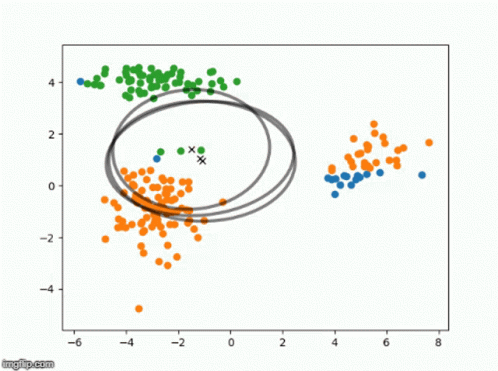
GMM berguna ketika cluster memiliki bentuk atau sebaran yang tidak harus sama. Namun, model ini juga memiliki asumsi distribusi dan perlu dievaluasi secara hati-hati.

In [17]:
# Mengimpor GaussianMixture dari modul mixture scikit-learn.
from sklearn.mixture import GaussianMixture

# Membuat GMM dengan jumlah komponen sama dengan kandidat jumlah cluster.
gmm_model = GaussianMixture(n_components=best_k, random_state=42)

# Melatih GMM dan menetapkan label cluster berdasarkan probabilitas tertinggi.
gmm_labels = gmm_model.fit_predict(X_scaled)

# Menambahkan label GMM ke tabel data.
df_model["gmm_cluster"] = gmm_labels

# Menghitung jumlah observasi pada setiap cluster GMM.
cluster_sizes_gmm = df_model["gmm_cluster"].value_counts().sort_index()

# Menampilkan ukuran cluster GMM.
display(cluster_sizes_gmm)

# Menghitung probabilitas keanggotaan setiap observasi pada seluruh komponen GMM.
gmm_probabilities = gmm_model.predict_proba(X_scaled)

# Mengubah probabilitas menjadi DataFrame dengan nama kolom yang jelas.
gmm_probabilities_df = pd.DataFrame(
    gmm_probabilities,
    columns=[f"probabilitas_cluster_{i}" for i in range(best_k)],
    index=df_model.index
)

# Menampilkan probabilitas keanggotaan untuk lima observasi pertama.
display(gmm_probabilities_df.head())

,count
gmm_cluster,
0,164
1,35
2,315


,probabilitas_cluster_0,probabilitas_cluster_1,probabilitas_cluster_2
0,0.00,0.00,1.00
1,0.00,0.00,1.00
2,0.00,0.01,0.99
3,0.00,0.00,1.00
4,0.00,0.00,1.00


## 15. Evaluasi dan perbandingan model clustering

Clustering tidak memiliki label jawaban yang benar seperti klasifikasi. Karena itu, metrik accuracy tidak tepat digunakan kecuali tersedia label eksternal yang memang ingin dibandingkan.

Metrik internal yang digunakan:
- **Silhouette Score:** semakin tinggi umumnya semakin baik.
- **Calinski-Harabasz Score:** semakin tinggi umumnya menunjukkan cluster yang lebih terpisah dan kompak.
- **Davies-Bouldin Score:** semakin rendah umumnya semakin baik.

Metrik tersebut bukan satu-satunya dasar pemilihan model. Periksa juga ukuran cluster, kestabilan, dan apakah profil cluster dapat dijelaskan secara ekonomi.

In [18]:
# Mengimpor tiga metrik evaluasi internal clustering.
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Menyimpan nama model dan label cluster masing-masing dalam sebuah dictionary.
model_labels = {
    "K-Means": kmeans_labels,
    "Hierarchical": hierarchical_labels,
    "Gaussian Mixture": gmm_labels
}

# Menyiapkan list kosong untuk menampung hasil evaluasi.
evaluation_results = []

# Menghitung metrik evaluasi untuk setiap model.
for model_name, labels in model_labels.items():
    # Menghitung Silhouette Score; nilai lebih tinggi umumnya lebih baik.
    silhouette = silhouette_score(X_scaled, labels)

    # Menghitung Calinski-Harabasz Score; nilai lebih tinggi umumnya lebih baik.
    calinski = calinski_harabasz_score(X_scaled, labels)

    # Menghitung Davies-Bouldin Score; nilai lebih rendah umumnya lebih baik.
    davies = davies_bouldin_score(X_scaled, labels)

    # Menyimpan nama model dan ketiga metrik ke dalam dictionary hasil.
    evaluation_results.append({
        "Model": model_name,
        "Silhouette Score": silhouette,
        "Calinski-Harabasz Score": calinski,
        "Davies-Bouldin Score": davies
    })

# Mengubah list hasil evaluasi menjadi DataFrame.
evaluation_df = pd.DataFrame(evaluation_results)

# Mengurutkan model berdasarkan Silhouette Score tertinggi dan menampilkan tabel.
display(evaluation_df.sort_values("Silhouette Score", ascending=False))

,Model,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,K-Means,0.28,223.46,1.19
1,Hierarchical,0.23,191.38,1.38
2,Gaussian Mixture,0.22,189.40,1.37


### Prinsip memilih model
Model dengan satu skor tertinggi belum tentu paling berguna. Pertimbangkan:
- apakah ada cluster yang terlalu kecil;
- apakah hasil berubah drastis ketika parameter atau sampel berubah;
- apakah profil setiap cluster berbeda secara substantif;
- apakah segmentasi dapat mendukung keputusan bisnis atau kebijakan;
- apakah hasilnya masuk akal berdasarkan konteks dan tahun data.

Nomor cluster (0, 1, 2, dan seterusnya) hanyalah kode. Cluster 0 tidak otomatis lebih baik daripada cluster 1.

## 16. Principal Component Analysis (PCA)

PCA adalah metode reduksi dimensi yang mengubah sejumlah fitur yang saling berkorelasi menjadi sejumlah komponen utama (*principal components*) yang tidak berkorelasi satu sama lain. PCA digunakan untuk mereduksi dimensi (jumlah variabel) dari suatu kumpulan data yang besar, sambil tetap mempertahankan informasi atau variasi terbanyak yang ada di dalamnya.

- PC1 menangkap variasi terbesar.
- PC2 menangkap variasi terbesar berikutnya yang tegak lurus terhadap PC1.
- Komponen berikutnya menangkap variasi tersisa secara berurutan.

PCA sering digunakan untuk merangkum informasi dan membantu visualisasi data berdimensi tinggi. PCA tidak melakukan clustering dan tidak otomatis memberi nama atau makna ekonomi pada komponen.

**Mengapa standardisasi dilakukan sebelum PCA?** Karena PCA sensitif terhadap skala variabel. Dalam praktikum ini, PCA dilakukan pada fitur yang telah distandardisasi.

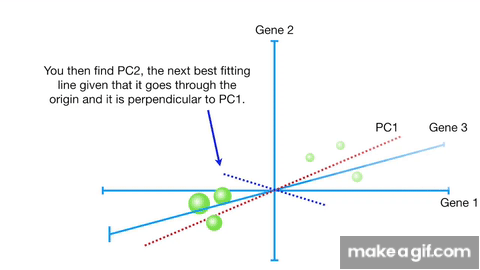

In [19]:
# Mengimpor PCA dari scikit-learn.
from sklearn.decomposition import PCA

# Membuat PCA yang merangkum data menjadi dua komponen agar dapat digambar dalam bidang 2D.
pca = PCA(n_components=2)

# Menghitung koordinat setiap observasi pada dua komponen utama.
X_pca = pca.fit_transform(X_scaled)

# Membuat DataFrame hasil PCA dengan nama kolom PC1 dan PC2.
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=df_model.index
)

# Menambahkan label K-Means agar titik pada grafik dapat dibedakan berdasarkan cluster.
pca_df["cluster"] = kmeans_labels

# Menampilkan proporsi variasi data yang dijelaskan oleh masing-masing komponen.
print("Proporsi variasi yang dijelaskan PC1 dan PC2:", pca.explained_variance_ratio_)

# Menjumlahkan proporsi variasi dua komponen untuk mengetahui total variasi yang terlihat pada grafik 2D.
print("Total variasi yang dijelaskan dua komponen:", pca.explained_variance_ratio_.sum())

Proporsi variasi yang dijelaskan PC1 dan PC2: [0.5752264  0.09322526]
Total variasi yang dijelaskan dua komponen: 0.6684516612640957


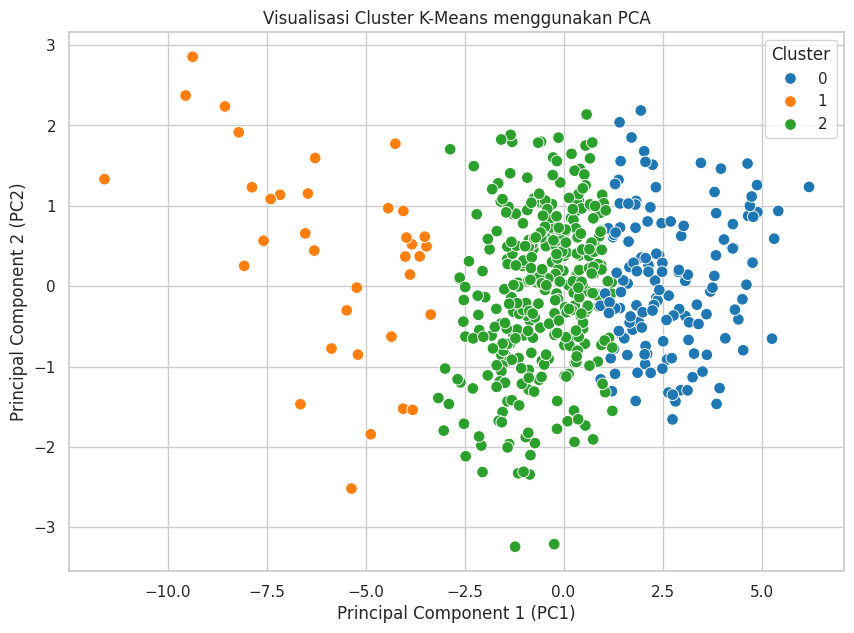

In [20]:
# Menentukan ukuran grafik PCA.
plt.figure(figsize=(10, 7))

# Membuat scatter plot PC1 dan PC2 dengan warna berbeda untuk setiap cluster.
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    s=70
)

# Memberikan judul grafik.
plt.title("Visualisasi Cluster K-Means menggunakan PCA")

# Menjelaskan bahwa sumbu horizontal adalah komponen utama pertama.
plt.xlabel("Principal Component 1 (PC1)")

# Menjelaskan bahwa sumbu vertikal adalah komponen utama kedua.
plt.ylabel("Principal Component 2 (PC2)")

# Menampilkan legenda dan grafik.
plt.legend(title="Cluster")
plt.show()

In [21]:
# Mengambil loading PCA dan mentransposenya agar setiap fitur menjadi satu baris.
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=clustering_features
)

# Mengurutkan fitur berdasarkan loading PC1 dari nilai terbesar ke terkecil.
display(loadings.sort_values("PC1", ascending=False))

,PC1,PC2
hdi,0.40,0.07
expenditure_per_capita,0.36,0.19
school_years,0.33,-0.24
sanitation_access,0.31,-0.07
log_regional_gdp,0.30,0.33
life_expectancy,0.30,0.52
unemployment_rate,0.29,-0.28
drinking_water_access,0.27,-0.19
labor_force_participation,-0.27,0.62
poverty_rate,-0.32,-0.15


### Cara menginterpretasikan PCA
1. Lihat persentase variasi yang dijelaskan PC1 dan PC2. Jika totalnya kecil, grafik 2D hanya menampilkan sebagian informasi.
2. Periksa *loading* untuk mengetahui fitur yang berkontribusi pada setiap komponen.
3. Perhatikan apakah cluster terpisah atau saling tumpang tindih pada bidang PCA.
4. Jangan menyebut PC1 sebagai “tingkat kesejahteraan” atau nama substantif lain tanpa memeriksa loading dan arah indikatornya.

Tanda positif/negatif pada komponen dapat dibalik secara matematis tanpa mengubah makna PCA. Karena itu, fokus pada pola relatif dan kontribusi fitur.

## 17. Profil ekonomi setiap cluster

Setelah model membentuk kelompok, kita perlu menjelaskan karakteristik kelompok tersebut. Salah satu langkah sederhana adalah menghitung rata-rata indikator untuk setiap cluster.

Tabel rata-rata menunjukkan nilai dalam satuan asli. Tabel z-score profil menunjukkan apakah rata-rata suatu cluster relatif lebih tinggi atau lebih rendah dibandingkan rata-rata antarcluster:
- z-score positif: di atas rata-rata antarcluster untuk indikator tersebut;
- z-score negatif: di bawah rata-rata antarcluster.

Z-score profil ini adalah alat bantu interpretasi, bukan ukuran kesejahteraan tunggal.

In [22]:
# Mengelompokkan data berdasarkan label K-Means dan menghitung rata-rata setiap fitur.
cluster_profile = df_model.groupby("kmeans_cluster")[clustering_features].mean()

# Menampilkan profil rata-rata indikator pada setiap cluster.
display(cluster_profile)

,poverty_rate,school_years,expenditure_per_capita,hdi,life_expectancy,sanitation_access,drinking_water_access,unemployment_rate,labor_force_participation,log_regional_gdp
kmeans_cluster,,,,,,,,,,
0,7.67,9.97,"13,243.74",76.90,72.73,89.23,96.19,7.83,65.89,17.04
1,30.72,5.36,"5,714.74",55.48,65.09,35.03,56.51,1.98,81.68,13.99
2,12.28,8.12,"9,584.49",68.51,68.85,76.55,83.49,4.22,69.69,15.80


In [23]:
# Menghitung rata-rata dan standar deviasi antarcluster untuk setiap indikator.
profile_mean = cluster_profile.mean()
profile_std = cluster_profile.std(ddof=0)

# Menghitung z-score profil cluster agar indikator dengan satuan berbeda lebih mudah dibandingkan.
profile_zscore = (cluster_profile - profile_mean) / profile_std.replace(0, np.nan)

# Membulatkan dua angka desimal dan menampilkan tabel profil relatif.
display(profile_zscore.round(2))

,poverty_rate,school_years,expenditure_per_capita,hdi,life_expectancy,sanitation_access,drinking_water_access,unemployment_rate,labor_force_participation,log_regional_gdp
kmeans_cluster,,,,,,,,,,
0,-0.93,1.14,1.21,1.13,1.23,0.96,1.06,1.31,-0.97,1.14
1,1.39,-1.30,-1.24,-1.30,-1.22,-1.38,-1.34,-1.12,1.38,-1.29
2,-0.46,0.16,0.02,0.18,-0.01,0.42,0.29,-0.19,-0.41,0.15


### Template interpretasi cluster
Gunakan profil aktual untuk menyusun narasi, misalnya:
- “Cluster A memiliki rata-rata IPM, lama sekolah, pengeluaran, dan akses sanitasi relatif lebih tinggi.”
- “Cluster B memiliki tingkat kemiskinan relatif tinggi dan indikator pembangunan manusia relatif lebih rendah.”
- “Cluster C menunjukkan karakteristik campuran, misalnya pengeluaran relatif tinggi tetapi pengangguran juga relatif tinggi.”

Hindari memberi nama cluster hanya berdasarkan satu variabel. Gunakan beberapa indikator dan konteks wilayah.

## 18. Contoh penerapan: segmentasi pasar dan rekomendasi

Bagian ini menggunakan **data pelanggan sintetis** (buatan untuk pembelajaran), bukan data pelanggan nyata. Tujuannya memperlihatkan bagaimana ide clustering wilayah dapat diterapkan pada pelanggan.

Variabel contoh:
- pendapatan bulanan;
- rata-rata pengeluaran bulanan;
- frekuensi transaksi per bulan;
- rata-rata nilai transaksi.

Setelah cluster terbentuk, kita dapat menyusun pendekatan pemasaran yang berbeda. Rekomendasi produk dalam contoh ini hanya ilustrasi berbasis profil kelompok, bukan sistem rekomendasi produksi.

In [24]:
# Mengimpor generator angka acak agar data sintetis dapat dibuat ulang secara konsisten.
rng = np.random.default_rng(42)

# Menentukan jumlah pelanggan sintetis untuk setiap segmen yang disimulasikan.
n_per_segment = 100

# Membuat kelompok pelanggan pertama dengan pendapatan dan belanja relatif rendah.
segment_1 = pd.DataFrame({
    "income_monthly": rng.normal(4_000_000, 800_000, n_per_segment),
    "spending_monthly": rng.normal(1_500_000, 300_000, n_per_segment),
    "transactions_per_month": rng.normal(3, 1, n_per_segment),
    "average_transaction": rng.normal(500_000, 100_000, n_per_segment)
})

# Membuat kelompok pelanggan kedua dengan pendapatan dan belanja menengah.
segment_2 = pd.DataFrame({
    "income_monthly": rng.normal(9_000_000, 1_500_000, n_per_segment),
    "spending_monthly": rng.normal(4_000_000, 700_000, n_per_segment),
    "transactions_per_month": rng.normal(6, 1.5, n_per_segment),
    "average_transaction": rng.normal(700_000, 150_000, n_per_segment)
})

# Membuat kelompok pelanggan ketiga dengan pendapatan dan nilai transaksi relatif tinggi.
segment_3 = pd.DataFrame({
    "income_monthly": rng.normal(20_000_000, 3_000_000, n_per_segment),
    "spending_monthly": rng.normal(10_000_000, 1_500_000, n_per_segment),
    "transactions_per_month": rng.normal(8, 2, n_per_segment),
    "average_transaction": rng.normal(1_250_000, 250_000, n_per_segment)
})

# Menggabungkan tiga kelompok sintetis menjadi satu dataset pelanggan.
customers = pd.concat([segment_1, segment_2, segment_3], ignore_index=True)

# Memastikan nilai transaksi dan frekuensi tidak negatif.
customers = customers.clip(lower=0)

# Menampilkan beberapa baris pertama dataset pelanggan sintetis.
display(customers.head())

,income_monthly,spending_monthly,transactions_per_month,average_transaction
0,"4,243,773.66","1,386,551.23",3.34,"672,735.02"
1,"3,168,012.72","1,889,768.49",4.41,"346,613.86"
2,"4,600,360.96","1,393,120.81",3.09,"586,382.80"
3,"4,752,451.77","1,721,254.67",3.64,"467,147.48"
4,"2,439,171.85","1,219,914.70",0.95,"493,867.57"


In [25]:
# Menentukan fitur pelanggan yang akan dipakai dalam segmentasi.
customer_features = [
    "income_monthly",
    "spending_monthly",
    "transactions_per_month",
    "average_transaction"
]

# Membuat scaler khusus pelanggan agar skala variabel menjadi sebanding.
customer_scaler = StandardScaler()

# Menstandardisasi fitur pelanggan.
customers_scaled = customer_scaler.fit_transform(customers[customer_features])

# Membuat model K-Means dengan tiga cluster sebagai contoh pembelajaran.
customer_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Melatih model dan mendapatkan label segmen pelanggan.
customers["customer_cluster"] = customer_kmeans.fit_predict(customers_scaled)

# Menghitung rata-rata profil pelanggan pada setiap cluster.
customer_profile = customers.groupby("customer_cluster")[customer_features].mean()

# Menampilkan profil setiap segmen pelanggan.
display(customer_profile.round(0))

,income_monthly,spending_monthly,transactions_per_month,average_transaction
customer_cluster,,,,
0,"9,045,340.00","3,935,080.00",6.00,"707,570.00"
1,"19,507,261.00","10,158,687.00",8.00,"1,242,320.00"
2,"4,276,328.00","1,699,023.00",3.00,"524,867.00"


### Mengubah profil menjadi strategi pemasaran

Setelah membaca tabel profil, susun strategi dengan format berikut:

| Temuan profil (berdasarkan output) | Ide strategi yang dapat diuji |
|---|---|
| Frekuensi transaksi relatif tinggi | Program loyalitas atau reward |
| Nilai transaksi rata-rata relatif rendah | Bundling atau cross-selling |
| Pengeluaran dan pendapatan relatif tinggi | Layanan premium atau penawaran eksklusif |
| Frekuensi transaksi relatif rendah | Kampanye aktivasi atau pengingat yang relevan |

Strategi harus disesuaikan dengan hasil nyata. Jangan menganggap nomor cluster tertentu selalu mewakili segmen tertentu karena nomor cluster dapat berubah antarproses pemodelan.

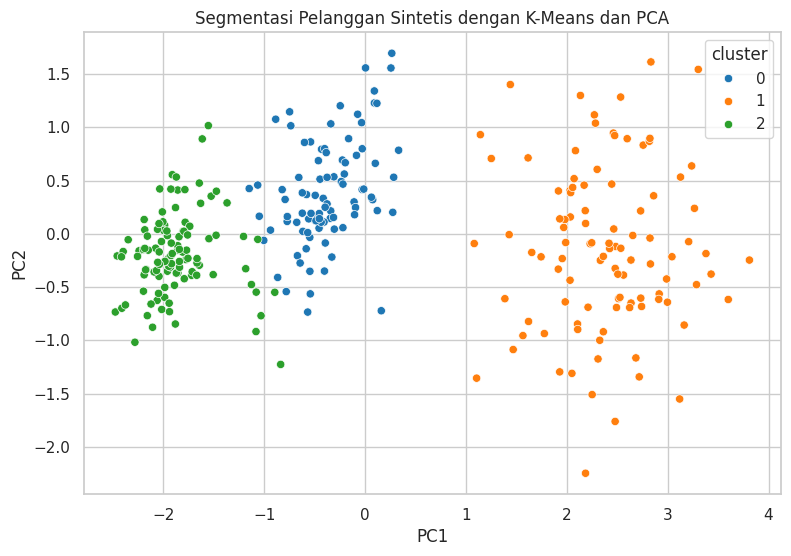

In [26]:
# Menghitung kembali PCA dua dimensi untuk data pelanggan yang telah distandardisasi.
customer_pca = PCA(n_components=2)

# Mengubah fitur pelanggan menjadi dua komponen utama.
customer_pca_values = customer_pca.fit_transform(customers_scaled)

# Membuat DataFrame koordinat PCA pelanggan.
customer_pca_df = pd.DataFrame(customer_pca_values, columns=["PC1", "PC2"])

# Menambahkan label cluster pelanggan ke DataFrame visualisasi.
customer_pca_df["cluster"] = customers["customer_cluster"].values

# Membuat area grafik.
plt.figure(figsize=(9, 6))

# Menggambar pelanggan pada bidang PCA dan membedakan warna berdasarkan cluster.
sns.scatterplot(data=customer_pca_df, x="PC1", y="PC2", hue="cluster", palette="tab10")

# Memberikan judul grafik.
plt.title("Segmentasi Pelanggan Sintetis dengan K-Means dan PCA")

# Menampilkan grafik.
plt.show()

### Clustering dan Recommendation System: ilustrasi sederhana
Misalnya sebuah perusahaan ingin merekomendasikan kategori produk kepada kelompok pelanggan. Langkah awalnya:
1. Kelompokkan pelanggan berdasarkan perilaku atau preferensi.
2. Hitung kategori produk yang paling sering dibeli oleh anggota setiap kelompok.
3. Rekomendasikan kategori populer dalam kelompok tersebut kepada pelanggan yang belum membelinya.
4. Evaluasi rekomendasi melalui eksperimen, misalnya click-through rate atau conversion rate.

Pada praktik nyata, dibutuhkan data interaksi pengguna-produk, penanganan *cold start*, pengukuran relevansi, serta perlindungan privasi.

In [27]:
# Membuat contoh riwayat pembelian sintetis untuk menunjukkan ide rekomendasi berbasis kelompok.
purchase_example = pd.DataFrame({
    "customer_cluster": [0, 0, 0, 1, 1, 1, 2, 2, 2],
    "product_category": ["Groceries", "Fashion", "Groceries", "Electronics", "Groceries", "Electronics",
                         "Premium", "Fashion", "Premium"]
})

# Menghitung jumlah kemunculan setiap kategori produk pada setiap cluster pelanggan.
recommendation_counts = purchase_example.groupby(
    ["customer_cluster", "product_category"]
).size().reset_index(name="jumlah_pembelian")

# Mengurutkan kategori yang paling sering muncul pada masing-masing cluster.
recommendation_counts = recommendation_counts.sort_values(
    ["customer_cluster", "jumlah_pembelian"],
    ascending=[True, False]
)

# Menampilkan kategori produk yang paling sering muncul per cluster.
display(recommendation_counts)

,customer_cluster,product_category,jumlah_pembelian
1,0,Groceries,2
0,0,Fashion,1
2,1,Electronics,2
3,1,Groceries,1
5,2,Premium,2
4,2,Fashion,1


## 19. Aplikasi utama: segmentasi wilayah ekonomi Indonesia

Kembali ke dataset kabupaten/kota. Kita akan menambahkan nama provinsi dan wilayah ke tabel hasil clustering agar kelompok dapat ditelusuri.

Hasil ini dapat menjadi titik awal untuk:
- pemetaan kelompok wilayah dengan karakteristik serupa;
- merancang program pembangunan yang lebih sesuai dengan kebutuhan;
- mengidentifikasi wilayah yang memerlukan kajian lebih lanjut;
- mendukung diskusi alokasi sumber daya.

**Batasan penting:** clustering bersifat deskriptif dan eksploratif. Hasilnya bukan bukti kausal, bukan peringkat resmi, dan bukan pengganti analisis kebijakan yang mempertimbangkan kondisi lokal.

In [28]:
# Menyiapkan kolom identitas wilayah yang tersedia pada dataset.
identity_columns = [column for column in ["province", "region"] if column in df_model.columns]

# Mengambil identitas wilayah dan label cluster K-Means untuk membuat tabel hasil.
regional_segments = df_model[identity_columns + ["kmeans_cluster"]].copy()

# Menampilkan beberapa wilayah beserta cluster hasil model.
display(regional_segments.head(20))

,province,region,kmeans_cluster
0,ACEH,Simeulue,2
1,ACEH,Aceh Singkil,2
2,ACEH,Aceh Selatan,2
3,ACEH,Aceh Tenggara,2
4,ACEH,Aceh Timur,2
5,ACEH,Aceh Tengah,2
6,ACEH,Aceh Barat,2
7,ACEH,Aceh Besar,0
8,ACEH,Pidie,2
9,ACEH,Bireuen,2


In [29]:
# Menggabungkan identitas wilayah dengan indikator ekonomi dan label cluster.
regional_results = df_model[identity_columns + clustering_features + ["kmeans_cluster"]].copy()

# Mengurutkan tabel berdasarkan cluster lalu nama wilayah jika kolom identitas tersedia.
sort_columns = ["kmeans_cluster"] + (["province", "region"] if "province" in regional_results.columns and "region" in regional_results.columns else [])

# Mengurutkan dan menampilkan hasil segmentasi wilayah.
display(regional_results.sort_values(sort_columns).head(30))

,province,region,poverty_rate,school_years,expenditure_per_capita,hdi,life_expectancy,sanitation_access,drinking_water_access,unemployment_rate,labor_force_participation,log_regional_gdp,kmeans_cluster
7,ACEH,Aceh Besar,14.05,10.33,"9,644.00",73.58,69.79,87.40,82.36,7.70,61.67,16.14,0
18,ACEH,Kota Banda Aceh,7.61,12.83,"16,891.00",85.71,71.52,99.88,99.37,8.94,63.00,16.55,0
20,ACEH,Kota Langsa,10.96,11.12,"12,067.00",77.44,69.43,91.81,97.14,7.21,67.04,15.20,0
21,ACEH,Kota Lhokseumawe,11.16,11.11,"11,390.00",77.57,71.64,93.10,94.44,11.16,63.91,15.80,0
275,BALI,Badung,2.62,10.62,"17,327.00",81.83,75.18,99.59,100.00,6.93,72.52,17.18,0
280,BALI,Buleleng,6.12,7.25,"13,362.00",72.56,71.95,94.15,93.38,5.38,73.08,16.90,0
276,BALI,Gianyar,4.85,9.29,"14,391.00",77.70,73.78,93.48,98.71,6.90,69.88,16.66,0
281,BALI,Kota Denpasar,2.96,11.48,"19,598.00",84.03,74.93,99.97,100.00,7.02,68.67,17.30,0
274,BALI,Tabanan,5.12,9.14,"14,326.00",76.45,73.75,98.34,98.15,3.94,74.98,16.49,0
270,BANTEN,Kota Cilegon,4.24,10.08,"13,041.00",73.35,66.69,97.07,98.72,10.13,61.37,18.16,0


### Contoh cara menerjemahkan hasil menjadi insight kebijakan
- Jika satu cluster menunjukkan kemiskinan relatif tinggi dan akses sanitasi relatif rendah, pemerintah dapat mengkaji kebutuhan intervensi perlindungan sosial dan infrastruktur dasar.
- Jika satu cluster menunjukkan IPM dan pendidikan relatif tinggi tetapi pengangguran juga tinggi, kajian lanjutan dapat berfokus pada keterkaitan pendidikan, keterampilan, dan pasar kerja.
- Jika cluster memiliki pengeluaran dan PDRB relatif tinggi tetapi indikator tertentu tertinggal, analisis dapat diarahkan pada ketimpangan di dalam wilayah.

Pernyataan di atas adalah contoh pola interpretasi. Gunakan nilai dan wilayah aktual dari output notebook sebelum menarik kesimpulan.

## 20. Menempatkan wilayah baru ke cluster K-Means

K-Means dapat menempatkan observasi baru ke centroid terdekat. Ini bukan prediksi label target seperti klasifikasi, melainkan penempatan ke salah satu cluster yang sudah dibentuk.

Contoh berikut adalah **wilayah hipotetis**, bukan data wilayah Indonesia yang sesungguhnya. Nilai fitur harus menggunakan satuan dan definisi yang sama dengan dataset pelatihan.

In [30]:
# Membuat satu baris data wilayah hipotetis dengan fitur yang sama seperti model.
new_region = pd.DataFrame({
    "poverty_rate": [12.0],
    "school_years": [9.5],
    "expenditure_per_capita": [11000],
    "hdi": [72.0],
    "life_expectancy": [70.0],
    "sanitation_access": [80.0],
    "drinking_water_access": [85.0],
    "unemployment_rate": [5.0],
    "labor_force_participation": [68.0],
    "log_regional_gdp": [np.log1p(5000000)]
})

# Menggunakan scaler yang sudah dipelajari dari data pelatihan; jangan melakukan fit ulang pada data baru.
new_region_scaled = scaler.transform(new_region[clustering_features])

# Menentukan cluster terdekat menggunakan model K-Means yang sudah dilatih.
new_cluster = kmeans_model.predict(new_region_scaled)

# Menampilkan nomor cluster untuk wilayah hipotetis.
print("Wilayah hipotetis ditempatkan pada cluster:", new_cluster[0])

Wilayah hipotetis ditempatkan pada cluster: 2


## 21. Eksperimen: membandingkan k = 3, 4, dan 5

Jumlah cluster yang paling baik secara statistik belum tentu paling mudah diterjemahkan menjadi strategi. Pada bagian ini, kita membandingkan tiga alternatif jumlah cluster untuk melihat trade-off antara kualitas pemisahan dan kemudahan interpretasi.

In [31]:
# Menyiapkan list untuk menyimpan ringkasan eksperimen k=3, k=4, dan k=5.
comparison_k_results = []

# Mengulangi pemodelan untuk tiga pilihan jumlah cluster.
for k in [3, 4, 5]:
    # Membuat model K-Means untuk nilai k saat ini.
    model_k = KMeans(n_clusters=k, random_state=42, n_init=10)

    # Melatih model dan memperoleh label cluster.
    labels_k = model_k.fit_predict(X_scaled)

    # Menyimpan nilai k dan Silhouette Score ke dalam list hasil.
    comparison_k_results.append({
        "jumlah_cluster": k,
        "silhouette_score": silhouette_score(X_scaled, labels_k),
        "inertia": model_k.inertia_
    })

# Mengubah ringkasan eksperimen menjadi DataFrame.
comparison_k_df = pd.DataFrame(comparison_k_results)

# Menampilkan perbandingan statistik k=3, k=4, dan k=5.
display(comparison_k_df)

,jumlah_cluster,silhouette_score,inertia
0,3,0.28,"2,741.90"
1,4,0.19,"2,397.74"
2,5,0.18,"2,204.96"


In [32]:
# Menjalankan ulang K-Means dengan tiga cluster untuk melihat ukuran dan profilnya.
model_k3 = KMeans(n_clusters=3, random_state=42, n_init=10)

# Menghasilkan label cluster untuk k=3.
labels_k3 = model_k3.fit_predict(X_scaled)

# Menghitung jumlah wilayah pada setiap cluster k=3.
sizes_k3 = pd.Series(labels_k3).value_counts().sort_index()

# Menampilkan ukuran cluster k=3.
display(sizes_k3)

# Menghitung rata-rata indikator asli untuk setiap cluster k=3.
profile_k3 = df_model.assign(cluster_k3=labels_k3).groupby("cluster_k3")[clustering_features].mean()

# Menampilkan profil ekonomi cluster k=3.
display(profile_k3)

,count
0,141
1,35
2,338


,poverty_rate,school_years,expenditure_per_capita,hdi,life_expectancy,sanitation_access,drinking_water_access,unemployment_rate,labor_force_participation,log_regional_gdp
cluster_k3,,,,,,,,,,
0,7.67,9.97,"13,243.74",76.90,72.73,89.23,96.19,7.83,65.89,17.04
1,30.72,5.36,"5,714.74",55.48,65.09,35.03,56.51,1.98,81.68,13.99
2,12.28,8.12,"9,584.49",68.51,68.85,76.55,83.49,4.22,69.69,15.80


In [33]:
# Menjalankan ulang K-Means dengan empat cluster.
model_k4 = KMeans(n_clusters=4, random_state=42, n_init=10)

# Menghasilkan label cluster untuk k=4.
labels_k4 = model_k4.fit_predict(X_scaled)

# Menghitung jumlah wilayah pada setiap cluster k=4.
sizes_k4 = pd.Series(labels_k4).value_counts().sort_index()

# Menampilkan ukuran cluster k=4.
display(sizes_k4)

# Menghitung rata-rata indikator asli untuk setiap cluster k=4.
profile_k4 = df_model.assign(cluster_k4=labels_k4).groupby("cluster_k4")[clustering_features].mean()

# Menampilkan profil ekonomi cluster k=4.
display(profile_k4)

,count
0,200
1,33
2,86
3,195


,poverty_rate,school_years,expenditure_per_capita,hdi,life_expectancy,sanitation_access,drinking_water_access,unemployment_rate,labor_force_participation,log_regional_gdp
cluster_k4,,,,,,,,,,
0,14.14,8.16,"8,945.89",67.26,67.48,72.75,81.52,3.74,70.68,15.32
1,31.28,5.26,"5,648.12",55.05,65.04,33.35,55.63,1.96,81.88,13.95
2,6.58,10.81,"14,338.80",79.38,72.84,91.57,97.55,8.48,65.07,17.01
3,9.66,8.21,"10,760.19",71.01,71.27,82.85,88.36,5.43,68.06,16.63


In [34]:
# Menjalankan ulang K-Means dengan lima cluster.
model_k5 = KMeans(n_clusters=5, random_state=42, n_init=10)

# Menghasilkan label cluster untuk k=5.
labels_k5 = model_k5.fit_predict(X_scaled)

# Menghitung jumlah wilayah pada setiap cluster k=5.
sizes_k5 = pd.Series(labels_k5).value_counts().sort_index()

# Menampilkan ukuran cluster k=5.
display(sizes_k5)

# Menghitung rata-rata indikator asli untuk setiap cluster k=5.
profile_k5 = df_model.assign(cluster_k5=labels_k5).groupby("cluster_k5")[clustering_features].mean()

# Menampilkan profil ekonomi cluster k=5.
display(profile_k5)

,count
0,123
1,165
2,84
3,31
4,111


,poverty_rate,school_years,expenditure_per_capita,hdi,life_expectancy,sanitation_access,drinking_water_access,unemployment_rate,labor_force_participation,log_regional_gdp
cluster_k5,,,,,,,,,,
0,9.87,8.14,"9,927.93",68.91,69.14,72.77,74.08,3.53,72.56,15.80
1,9.95,8.24,"10,796.68",71.28,71.47,84.30,90.84,5.66,67.60,16.70
2,6.59,10.84,"14,378.20",79.46,72.86,91.56,97.64,8.53,65.03,17.03
3,31.13,5.09,"5,650.81",54.65,64.92,29.96,55.14,1.91,82.22,13.99
4,17.42,8.17,"8,300.99",66.10,66.43,73.89,87.83,4.12,68.59,15.02


## 22. Latihan dan pertanyaan diskusi webinar

### Latihan 1 — Konsep
1. Jelaskan perbedaan Supervised Learning dan Unsupervised Learning.
2. Mengapa clustering termasuk Unsupervised Learning?
3. Berikan contoh Regression, Classification, dan Clustering dalam konteks ekonomi Indonesia.
4. Sebutkan minimal tiga metode Unsupervised Learning selain K-Means.

### Latihan 2 — Pemahaman algoritma
1. Bagaimana K-Means menentukan centroid?
2. Apa perbedaan pendekatan K-Means dan Agglomerative Clustering?
3. Apa fungsi dendrogram?
4. Mengapa standardisasi penting sebelum clustering?
5. Apa perbedaan hard clustering dan soft clustering?

### Latihan 3 — Interpretasi model
1. Berdasarkan Elbow Method, nilai k berapa yang menjadi kandidat?
2. Nilai k mana yang menghasilkan Silhouette Score tertinggi?
3. Apakah cluster memiliki ukuran yang seimbang?
4. Model mana yang paling mudah diinterpretasikan secara ekonomi? Jelaskan alasannya.

### Latihan 4 — PCA
1. Apa tujuan PCA?
2. Berapa proporsi variasi yang dijelaskan PC1 dan PC2?
3. Fitur apa yang memiliki loading besar pada PC1?
4. Apakah visualisasi 2D sudah cukup mewakili seluruh informasi data?

### Latihan 5 — Aplikasi ekonomi
1. Bagaimana pemerintah dapat menggunakan segmentasi wilayah untuk menyusun prioritas pembangunan?
2. Bagaimana perusahaan dapat menggunakan clustering untuk targeted marketing?
3. Bagaimana clustering dapat mendukung recommendation system?
4. Apa risiko jika hasil cluster digunakan sebagai satu-satunya dasar alokasi anggaran?

### Tugas mini
Pilih satu aplikasi (segmentasi pelanggan atau wilayah ekonomi). Buat ringkasan 1–2 halaman yang memuat:
- tujuan analisis;
- variabel yang digunakan;
- algoritma yang dipilih dan alasan;
- hasil cluster;
- profil setiap cluster;
- rekomendasi bisnis/kebijakan;
- keterbatasan analisis.

## 23. Ringkasan materi

- **Supervised Learning** menggunakan data berlabel untuk memprediksi target; **Unsupervised Learning** mencari pola tanpa target yang disediakan.
- Unsupervised Learning mencakup clustering, reduksi dimensi, association rules, dan anomaly detection.
- **Clustering** mengelompokkan observasi berdasarkan kemiripan.
- **Regression** menghasilkan angka, **Classification** memprediksi kelas yang telah ditentukan, dan **Clustering** menemukan kelompok dari data.
- **K-Means** membentuk cluster berdasarkan centroid.
- **Hierarchical/Agglomerative Clustering** menggabungkan cluster secara bertahap dan dapat divisualisasikan dengan dendrogram.
- **GMM** menyediakan probabilitas keanggotaan cluster.
- **PCA** merangkum variasi data ke dalam komponen utama dan membantu visualisasi.
- Segmentasi pasar dan wilayah ekonomi memerlukan interpretasi berbasis profil, konteks, serta pertimbangan etika dan kebijakan.

## 24. Referensi dan dokumentasi

### Dataset
- Repositori GitHub: https://github.com/JangAY/Klasifikasi_Kemiskinan_Indonesia
- Deskripsi dataset Kaggle yang tercantum pada notebook sumber: https://www.kaggle.com/datasets/ldausl/klasifikasi-tingkat-kemiskinan-di-indonesia

### Dokumentasi metode
- Scikit-learn — Clustering: https://scikit-learn.org/stable/modules/clustering.html
- Scikit-learn — K-Means: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
- Scikit-learn — Agglomerative Clustering: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html
- Scikit-learn — Gaussian Mixture: https://scikit-learn.org/stable/modules/mixture.html
- Scikit-learn — PCA: https://scikit-learn.org/stable/modules/decomposition.html#pca
- Scikit-learn — StandardScaler: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

### Catatan akademik
Notebook ini merupakan materi pembelajaran. Hasil clustering bergantung pada pemilihan fitur, kualitas data, preprocessing, algoritma, dan parameter. Validasi substantif dan konteks ekonomi diperlukan sebelum hasil digunakan untuk keputusan nyata.